# Step 1 — Preprocessing & Data Understanding (JDSearch)

**Purpose.** Parse the raw `user_behavior_data.txt` into three tidy tables that later notebooks reuse, and document the data findings that shape our feature engineering, in particular the *per-type retention windows* in the user history, which the interim-report feedback asked us to investigate.

| Output (saved to `OUT_DIR`) | Grain | Columns |
|---|---|---|
| `events.parquet` | one historical interaction | `user, pos, wid, type, age_days, qry` |
| `candidates.parquet` | one exposed candidate in the test slate | `user, pos, wid, label` |
| `users.parquet` | one test query (= one user) | `user, query, n_hist, n_cand` |
| `queries.parquet` | query vocabulary | `qry, text` (history and test queries share codes) |

*Exploration from the interim report (slate lengths, position leakage, query-term matching, category hierarchy) lives in `JDSearch_Data_Anlaysis.ipynb` and is not repeated here.*

**Runtime.** About 3 minutes and under 6 GB RAM on a standard Colab CPU runtime.

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:                                    # Colab: data lives on the shared Drive
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/JDSearch/Raw Data')
except ImportError:                     # local run: set JD_DATA_DIR or use the default download location
    DATA_DIR = Path(os.environ.get('JD_DATA_DIR', '~/Downloads/JDsearch')).expanduser()

USER_TXT = DATA_DIR / 'user_behavior_data.txt'
OUT_DIR = DATA_DIR / 'processed'
OUT_DIR.mkdir(parents=True, exist_ok=True)

TYPE_NAMES = ['CLICK', 'CART', 'ORD', 'FLW']          # integer codes 0..3 used in events.type
TYPE_CODE = {t: i for i, t in enumerate(TYPE_NAMES)}
DAY = 86400.0
print('Reading', USER_TXT)

Reading /Users/emmyli/Downloads/JDsearch/user_behavior_data.txt


## 1. Parse the raw file into flat tables

Each line is one user: a test query with its candidate slate and labels, plus four aligned history lists.

- `history_time_list` has **one more entry** than the other history lists. Entry 0 is always `0`. Entry *i* is the gap in seconds between history events *i−1* and *i*, and the last entry is the gap from the last history event to the test query.
- So the age of history event *j* (time before the test query) = the sum of all gaps after it = a reverse cumulative sum of `history_time_list[1:]`.
- Parsing straight into numpy arrays, rather than keeping Python lists inside a DataFrame, is what brings memory down from >12.7 GB (which crashed the original notebook) to a few GB.

In [2]:
def parse_user_file(path):
    vocab = {'-1': -1}                                  # query string -> integer code (-1 = query-less behaviour)
    enc = lambda q: vocab.setdefault(q, len(vocab) - 1)
    ev = {k: [] for k in ('user', 'pos', 'wid', 'type', 'age', 'qry')}
    cand = {k: [] for k in ('user', 'pos', 'wid', 'label')}
    users = []
    with open(path, encoding='utf-8') as f:
        header = f.readline().rstrip('\n').split('\t')
        assert header[0] == 'query' and header[-1] == 'history_time_list', header
        for u, line in enumerate(f):
            query, c_wid, c_lab, h_qry, h_wid, h_type, h_time = line.rstrip('\n').split('\t')
            # --- candidate slate (test query) ---
            cw = np.array(c_wid.split('_'), dtype=np.int64)
            cl = np.array(c_lab.split('_'), dtype=np.float32).astype(np.int8)
            m = len(cw)
            cand['user'].append(np.full(m, u, np.int32)); cand['pos'].append(np.arange(m, dtype=np.int16))
            cand['wid'].append(cw); cand['label'].append(cl)
            # --- history ---
            hw = h_wid.split('_'); n = len(hw)
            gaps = np.array(h_time.split('_'), dtype=np.float64)
            assert len(gaps) == n + 1 and gaps[0] == 0, f'user {u}: time list misaligned'
            ev['user'].append(np.full(n, u, np.int32)); ev['pos'].append(np.arange(n, dtype=np.int32))
            ev['wid'].append(np.array(hw, dtype=np.int64))
            ev['type'].append(np.array([TYPE_CODE[t] for t in h_type.split('_')], dtype=np.int8))
            ev['age'].append((np.cumsum(gaps[1:][::-1])[::-1] / DAY).astype(np.float32))
            ev['qry'].append(np.array([enc(q) for q in h_qry.split('_')], dtype=np.int32))
            users.append((u, enc(query), query, n, m))
    events = pd.DataFrame({k: np.concatenate(v) for k, v in ev.items()}).rename(columns={'age': 'age_days'})
    candidates = pd.DataFrame({k: np.concatenate(v) for k, v in cand.items()})
    users = pd.DataFrame(users, columns=['user', 'qry', 'query', 'n_hist', 'n_cand'])
    queries = pd.DataFrame({'qry': list(vocab.values()), 'text': list(vocab.keys())})
    return events, candidates, users, queries

t0 = time.time()
events, candidates, users, queries = parse_user_file(USER_TXT)
print(f'parsed in {time.time() - t0:.0f}s')
print(f'events {events.shape} | candidates {candidates.shape} | users {users.shape} | distinct queries {len(queries) - 1:,}')

parsed in 17s
events (26667260, 6) | candidates (15510012, 4) | users (173831, 5) | distinct queries 1,740,830


In [3]:
overview = pd.Series({
    'users (= test queries)': len(users),
    'history interactions': len(events),
    'candidate exposures': len(candidates),
    'distinct products in history': events['wid'].nunique(),
    'distinct products in candidate slates': candidates['wid'].nunique(),
    'distinct history queries (excl. -1)': events.loc[events['qry'] >= 0, 'qry'].nunique(),
    'history span: max age (days)': round(float(events['age_days'].max()), 1),
}, dtype=object).to_frame('value')
overview

,value
users (= test queries),173831
history interactions,26667260
candidate exposures,15510012
distinct products in history,5584543
distinct products in candidate slates,8362535
distinct history queries (excl. -1),1691282
history span: max age (days),635.3


## 2. The history is truncated by interaction type (the professor's question)

The interim report showed **carts (11.5M) > clicks (8.3M) > orders (6.8M)** in the history and read this as users skipping funnel steps. A normal e-commerce funnel has roughly 5–10 clicks per cart and 3–5 carts per order. Below we convert each event to *days before the test query* and look at how each type is distributed over time.

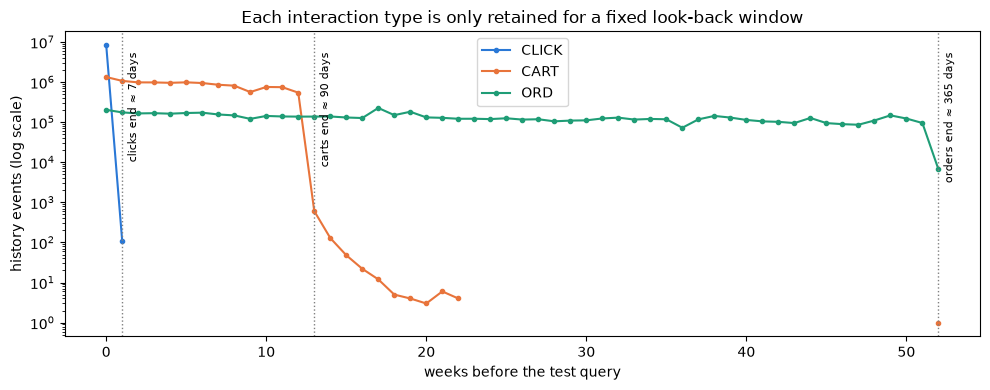

In [4]:
week = np.minimum(events['age_days'].to_numpy() // 7, 52).astype(int)
weekly = pd.crosstab(week, pd.Categorical.from_codes(events['type'], TYPE_NAMES)).reindex(columns=TYPE_NAMES)

fig, ax = plt.subplots(figsize=(10, 4))
for t, c in zip(TYPE_NAMES[:3], ['#2a78d6', '#e8743b', '#1f9d76']):
    ax.plot(weekly.index, weekly[t].replace(0, np.nan), marker='o', ms=3, label=t, color=c)
ax.set_yscale('log'); ax.set_xlabel('weeks before the test query'); ax.set_ylabel('history events (log scale)')
ax.set_title('Each interaction type is only retained for a fixed look-back window')
for d, lbl in [(1, 'clicks end ≈ 7 days'), (13, 'carts end ≈ 90 days'), (52, 'orders end ≈ 365 days')]:
    ax.axvline(d, color='grey', ls=':', lw=1); ax.text(d + 0.3, ax.get_ylim()[1] * 0.3, lbl, fontsize=8, rotation=90, va='top')
ax.legend(); plt.tight_layout(); plt.show()

In [5]:
daily = pd.crosstab(np.minimum(events['age_days'].to_numpy() // 1, 15).astype(int),
                    pd.Categorical.from_codes(events['type'], TYPE_NAMES)).reindex(columns=TYPE_NAMES)
daily.index = [f'{d}' if d < 15 else '15+' for d in daily.index]
daily.index.name = 'days before query'
daily

col_0,CLICK,CART,ORD,FLW
days before query,,,,
0,1918289,287228,36441,616
1,1310907,193885,28426,294
2,1223546,181830,28607,335
3,1145341,172236,27337,434
4,1111199,169568,27324,304
5,1068745,167673,27500,359
6,520760,162737,27187,309
7,5,164231,27421,208
8,32,160254,26924,478


In [6]:
retention = pd.DataFrame({
    t: np.percentile(events.loc[events['type'] == i, 'age_days'], [50, 90, 99, 99.9, 100])
    for i, t in enumerate(TYPE_NAMES)
}, index=['median', 'p90', 'p99', 'p99.9', 'max']).round(2).T
retention['events'] = events['type'].value_counts().sort_index().to_numpy()
retention['events beyond window'] = [
    int(((events['type'] == i) & (events['age_days'] >= w)).sum()) for i, w in enumerate([7, 90, 365, 90])]
retention   # FLW (follow) behaves like CART (~90 days) and is <0.1% of events

,median,p90,p99,p99.9,max,events,events beyond window
CLICK,2.79,5.75,6.49,6.89,13.15,8298894,107
CART,38.37,78.16,88.31,89.46,635.29,11526504,1204
ORD,154.08,320.17,359.58,364.00,364.99,6817283,0
FLW,39.44,79.21,87.70,89.37,89.99,24579,0


**Reading the result**

- **Clicks** exist only for the last ~7 days (day 6 is a half day, and only ~100 stray clicks fall after it).
- **Carts** stop at ~90 days (a few hundred after that).
- **Orders** cover the full year.

This is how the dataset was *recorded*, not how users behave. The next cell shows that once all types are compared over the same window, the funnel looks normal.

In [7]:
def funnel_in_window(days):
    c = np.bincount(events.loc[events['age_days'] < days, 'type'], minlength=4)
    return {'window': f'last {days} d', 'clicks': c[0], 'carts': c[1], 'orders': c[2],
            'clicks per cart': round(c[0] / c[1], 2), 'carts per order': round(c[1] / c[2], 2)}

funnel = pd.DataFrame([funnel_in_window(d) for d in (7, 90, 366)]).set_index('window')
funnel.index = ['last 7 d (all types recorded)', 'last 90 d (no clicks before day 7)', 'whole history (what the interim report used)']
funnel

,clicks,carts,orders,clicks per cart,carts per order
last 7 d (all types recorded),8298787,1335157,202822,6.22,6.58
last 90 d (no clicks before day 7),8298894,11525300,2035925,0.72,5.66
whole history (what the interim report used),8298894,11526503,6817283,0.72,1.69


Inside the 7-day window where all types are recorded, there are **~6.2 clicks per cart and ~6.6 carts per order**, in line with a normal e-commerce funnel. Across the whole history the funnel looks inverted only because older clicks and carts were never kept.

### 2.1 Consequences for our earlier analysis and features

In [8]:
# (a) User-level funnel ratios mostly measure how far back a user's history goes
nU = len(users)
def per_user(mask):
    return np.bincount(events.loc[mask, 'user'], minlength=nU)

clicks_all, carts_all = per_user(events['type'] == 0), per_user(events['type'] == 1)
in7 = events['age_days'] < 7
clicks_7, carts_7 = per_user(in7 & (events['type'] == 0)), per_user(in7 & (events['type'] == 1))
span = events.groupby('user')['age_days'].max().reindex(range(nU)).to_numpy()

naive = carts_all / np.maximum(clicks_all, 1)
windowed = carts_7 / np.maximum(clicks_7, 1)
print(f"users with no click at all (no activity in the last 7 days): {np.mean(clicks_all == 0):.1%}")
print(f"mean user cart:click ratio - whole history (interim report hist_cart_to_click_ratio): {naive[clicks_all > 0].mean():.2f}")
print(f"mean user cart:click ratio - last 7 days only:                                        {windowed[clicks_7 > 0].mean():.2f}")
print(f"Spearman corr(history span, whole-history ratio) = "
      f"{pd.Series(span).corr(pd.Series(naive), method='spearman'):.2f}  vs  "
      f"corr(history span, 7-day ratio) = {pd.Series(span).corr(pd.Series(windowed), method='spearman'):.2f}")

users with no click at all (no activity in the last 7 days): 16.2%
mean user cart:click ratio - whole history (interim report hist_cart_to_click_ratio): 3.76
mean user cart:click ratio - last 7 days only:                                        0.20


Spearman corr(history span, whole-history ratio) = 0.23  vs  corr(history span, 7-day ratio) = 0.12


In [9]:
# (b) The 'CART -> CLICK' transitions in the interim report (Figure 7) come from the truncation
ev_s = events[events['type'] < 3].sort_values(['user', 'wid', 'pos'], kind='stable')
same_item = (ev_s['user'].to_numpy()[1:] == ev_s['user'].to_numpy()[:-1]) & (ev_s['wid'].to_numpy()[1:] == ev_s['wid'].to_numpy()[:-1])
src_t, dst_t = ev_s['type'].to_numpy()[:-1][same_item], ev_s['type'].to_numpy()[1:][same_item]
src_age = ev_s['age_days'].to_numpy()[:-1][same_item]
trans = pd.DataFrame({'from': np.array(TYPE_NAMES)[src_t], 'to': np.array(TYPE_NAMES)[dst_t], 'src_age': src_age})
trans = trans[trans['from'] != trans['to']]
summary = trans.groupby(['from', 'to']).agg(n=('src_age', 'size'),
                                            share_first_event_older_than_7d=('src_age', lambda a: np.mean(a >= 7)))
summary.sort_values('n', ascending=False).round(3)

n  share_first_event_older_than_7d
from  to                                             
CART  ORD    1720352                            0.933
CLICK CART    917399                            0.000
CART  CLICK   763958                            0.240
ORD   CART    458035                            0.993
      CLICK   153179                            0.443
CLICK ORD      68906                            0.000

- Clicks only exist in the last 7 days, so an item first carted earlier than that can **never** have its preceding click recorded. That is why `CLICK → CART` (917k) looks rare next to the carts it should precede: 93% of `CART → ORD` and 99% of `ORD → CART` sequences start outside the click window.
- `CART → CLICK` is mostly real behaviour: 76% start from a cart in the last 7 days, i.e. users re-opening an item they had already carted. It is a revisit, not evidence that the funnel runs backwards.
- So the history's type mix and transition order can't be used to argue that users "skip steps". The ordinal target (0 < click < cart < purchase) is still valid, but for a different reason: the test label records the **strongest** interaction with each candidate in a fully recorded session.

In [10]:
# (c) Query-less behaviour (history_qry_list = -1) is NOT a truncation artefact: its share is stable across windows
ql = (events['qry'] == -1).to_numpy()
rows = []
for i, t in enumerate(TYPE_NAMES[:3]):
    m = events['type'].to_numpy() == i
    rows.append({'type': t, 'query-less share (whole history)': ql[m].mean(),
                 'query-less share (last 7 d)': ql[m & in7.to_numpy()].mean()})
pd.DataFrame(rows).set_index('type').round(3)

,query-less share (whole history),query-less share (last 7 d)
type,,
CLICK,0.717,0.717
CART,0.689,0.691
ORD,0.490,0.469


About 70% of clicks and carts (and ~50% of orders) happen outside search, e.g. from the homepage or recommendations. That share doesn't change with the window, so it reflects real behaviour. These events are **preference signal for personalisation**, not noise to drop (the interim report suggested ignoring them).

## 3. Query-field checks

In [11]:
hist_q = events.loc[events['qry'] >= 0, ['user', 'qry']].drop_duplicates()
exact = users[['user', 'qry']].merge(hist_q, on=['user', 'qry']).shape[0]
print(f"test query appears verbatim in the user's own history: {exact} of {len(users):,} users")

tok = queries.set_index('qry')['text'].str.split('\x18')          # term ids inside a query are separated by \x18 (^X)
q_tokens = users['qry'].map(tok)
hist_tokens = (hist_q.assign(t=hist_q['qry'].map(tok)).explode('t').groupby('user')['t'].agg(set))
overlap = np.array([len(set(q) & hist_tokens.get(u, set())) / len(q) for u, q in zip(users['user'], q_tokens)])
print(f"users whose test query shares >=1 term with a past query: {np.mean(overlap > 0):.1%} "
      f"(mean share of query terms seen before: {overlap.mean():.2f})")

rep_all = users['n_hist'] - events.groupby('user')['qry'].nunique().reindex(users['user']).to_numpy()
rep_real = (events[events['qry'] >= 0].groupby('user')['qry'].agg(lambda s: len(s) - s.nunique())
            .reindex(users['user']).fillna(0).to_numpy())
print(f"qry_repeats median: {np.median(rep_all):.0f} counting '-1' placeholders vs {np.median(rep_real):.0f} for real queries only")

test query appears verbatim in the user's own history: 1 of 173,831 users


users whose test query shares >=1 term with a past query: 41.2% (mean share of query terms seen before: 0.24)


qry_repeats median: 57 counting '-1' placeholders vs 11 for real queries only


- `query_in_history` (an exact match) is effectively constant: the test query never repeats verbatim. **Replace it with term overlap**, which is non-zero for ~41% of users.
- `qry_repeats` in the interim report counted the `-1` placeholders as repeated queries. **Recompute it on real queries only.**

## 4. Roles of the data fields (how we will use each one)

| Field(s) | Role | Notes |
|---|---|---|
| `history_*` lists | **Input only** (user context) | Positive-only, with per-type retention windows (click 7 d, cart 90 d, order 365 d). Never used as training labels: they contain no exposures/negatives. |
| `candidate_wid_list` + `candidate_label_list` | **The only labelled samples** | The only impression data (exposed and not exposed). Train/validation/test splits are made **by user** over these slates. |
| candidate position (`pos`) | **Excluded** | Interacted items are always listed first, so position leaks the label (interim §2.2.1). Slates are shuffled before modelling. |
| `query` (test) | **Context for relevance** | This is a personalised *search re-ranking* task: query-to-product relevance is central. |
| `history_qry_list = -1` | **Preference signal** | Non-search behaviour, about 70% of clicks/carts. Kept as user taste, not as search success. |

Because each user has exactly one test slate, **user-level features are constant within a slate**. On their own they can't change the ranking inside a query; they only help through interactions with candidate-level features (e.g. a high-intent user × the candidate's price or category).

## 5. Save processed tables

In [12]:
for name, df in [('events', events), ('candidates', candidates), ('users', users), ('queries', queries)]:
    df.to_parquet(OUT_DIR / f'{name}.parquet', index=False)
    print(f'saved {name:<10} {df.shape} -> {OUT_DIR / (name + ".parquet")}')

saved events     (26667260, 6) -> /Users/emmyli/Downloads/JDsearch/processed/events.parquet


saved candidates (15510012, 4) -> /Users/emmyli/Downloads/JDsearch/processed/candidates.parquet
saved users      (173831, 5) -> /Users/emmyli/Downloads/JDsearch/processed/users.parquet


saved queries    (1740831, 2) -> /Users/emmyli/Downloads/JDsearch/processed/queries.parquet
